# Lab 3: Prox Gradient and Accelerated Methods


In [ ]:
import numpy as np

import matplotlib.pyplot as plt

rnd_state = np.random.RandomState(12)

## Introduzione: Proximal gradient
Definiamo il proximity operator come segue
$$
\text{prox}_{\lambda f}(v) = \arg \min\limits_{x \in \mathbb{R}^d} \Big\{ f(x) + \frac{1}{2 \lambda} \| x - v \|^2 \Big\}
$$
Dato un punto $v \in \mathbb{R}^d$, $\text{prox}_{\lambda f}(v)$ e\` un punto vicino a $v$ e verso un minimizzatore di $f$. Il parametro $\lambda$ puo\` essere interpretato come un peso relativo tra i due termini.

Inoltre e\` possibile provare che $x^*$ minimizza $f$ se e solo se $x^*$ e\` un punto fisso dell'operatore i.e.
$$
x^* \in \arg \min\limits_{x \in \mathbb{R}^d} f(x) \iff x^* = \text{prox}_{\lambda f}(x^*)
$$



Consideriamo il seguente problema di ottimizzazione
$$
\min\limits_{x \in \mathbb{R}^d} F(x) := f(x) + g(x).
$$
Assumiamo inoltre che $f$ sia convessa differenziabile, $L$-smooth e $g$ convessa. Assumiamo inoltre che il prox operator possa essere calcolato in forma chiusa per ogni $\gamma > 0$.

Dato un $x_0 \in \mathbb{R}^d$, l'iterazione di proximal gradient e` definita come segue
$$
x_{k+1} = \text{prox}_{\gamma g}(x_k - \gamma \nabla f(x_k))
$$
Con $\gamma \in (0, 2/L)$ la sequenza $(x_k)_{k \in \mathbb{N}}$ converge a un minimizzatore di $F$.

### Constrained Optimization
La prima cosa che possiamo notare e\` che il proximity operator e\` una generalizzazione dell'operatore di proiezione per i problemi di ottimizzazione vincolata.
Infatti, sia $f$ una funzione convessa e differenziabile e sia $C$ un set convesso. Consideriamo il seguente problema di ottimizzazione
$$
\min\limits_{x \in C} f(x)
$$
Con $C \subseteq \mathbb{R}^d$. Il problema puo\` essere riformulato come segue
$$
\min\limits_{x \in \mathbb{R}^d} f(x) + I_C(x)
$$
Dove $I_C$ e\` la funzione indicatrice definita come segue
$$
I_C(x) = \left\{ \begin{array}{ll}
    0 & \text{if }x\in C\\
    \infty & \text{otherwises}
    \end{array}
  \right.
$$
In questo caso, il prox operator e\` definito come segue
$$
\text{prox}(v) = \Pi_C (x) := \arg\min\limits_{x \in C} \| x - v \|_2
$$

Consideriamo, ad esempio, il caso $f(x) := \frac{1}{2} \| A x -v \|^2$ con:
- $A \in \mathbb{R}^{d \times d}$ (full rank)
- il set $C$ e\` un ipercubo $[-2, 2]^{d}$ con $d = 10$





In [ ]:
d = 10
A = rnd_state.randn(d, d) # inizializza la matrice A con valori random
x_star = np.full(d, 3.0)
v = A @ x_star
def f(x):
  return 0.5 * np.square(np.linalg.norm((A @ x) - v, ord=2))

Implementiamo ora la funzione `grad_f` e `prox` che prendono in input una $x$ e restituiscono il gradiente di $f$ in $x$ e il prox rispettivamente.

**Hint:** dato che il constraint e\` rappresentato da un ipercubo possiamo usare la funzione [np.clip](https://numpy.org/doc/stable/reference/generated/numpy.clip.html) #quando un entrata e' maggiore del costraint, la clippa, la taglia (proietta?)

In [ ]:
def grad_f(x):
  # TODO: return il gradiente di f in x
  return np.transpose(A) @ ((A @ x) - v)

C = np.array([[-2, 2] for _ in range(d)])

def prox(x):
  # TODO: return il prox in x
  return np.clip(x-v, C[:,0], C[:,1])


Implementiamo inoltre una funzione per plottare function values e la sequenza $\| x_k - x^* \|$ (dove $x^* \in \arg\min\limits_{x \in \mathbb{R}^d} f$(x))

In [ ]:
# funzione per plottare i function values e |x_k - x^star|
def plot_fvals(f_vals, x_norms, yscale=None):
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
  ax1.set_title("Function values", fontsize=18)
  ax2.set_title("Norm of iterates", fontsize=18)
  ax1.plot(range(len(f_vals)), f_vals, '-', c='black', lw=3)
  ax2.plot(range(len(x_norms)), x_norms, '-', c='black', lw=3)
  if yscale is not None:
    ax1.set_yscale(yscale)
  ax2.set_yscale("log")
  ax1.set_xlabel("$k$", fontsize=16)
  ax2.set_xlabel("$k$", fontsize=16)
  ax1.set_ylabel("$f(x_k) - f(x^*)$", fontsize=16)
  ax2.set_ylabel("$\| x_k - x^* \|$", fontsize=16)
  fig.tight_layout()




Implementiamo ora l'iterazione
$$
x_{k + 1} = \Pi_C (x_k - \gamma \nabla f(x_k))
$$

In [ ]:
def pg_descent(x_0, gamma, T = 100):
  f_vals = np.zeros(T + 1)
  x_iters = np.zeros((T + 1, x0.shape[0]))

  x = x_0.copy()
  f_vals[0] = f(x) - f(x_star)
  x_iters[0] = x.copy() - x_star
  for t in range(T):
    # TODO: implementa l'iterazione proposta sopra
    x = prox(x-gamma*grad_f(x))
    f_vals[t + 1] = f(x) - f(x_star)
    x_iters[t + 1] = x.copy() - x_star

  return x, f_vals, x_iters




Minimizziamo ora la funzione target usando l'algoritmo implementato.

In [ ]:
# TODO: scegli un valore ragionevole per gamma

AtA=np.dot(np.transpose(A),A)
eigenvalues=np.linalg.eigvalsh(AtA)
mu=np.min(eigenvalues)
L=np.max(eigenvalues)
gamma=2/(L+mu)


T = 100
x0 = np.full(d, 1.0)

x, f_vals, x_iters = pg_descent(x0, gamma, T = T)


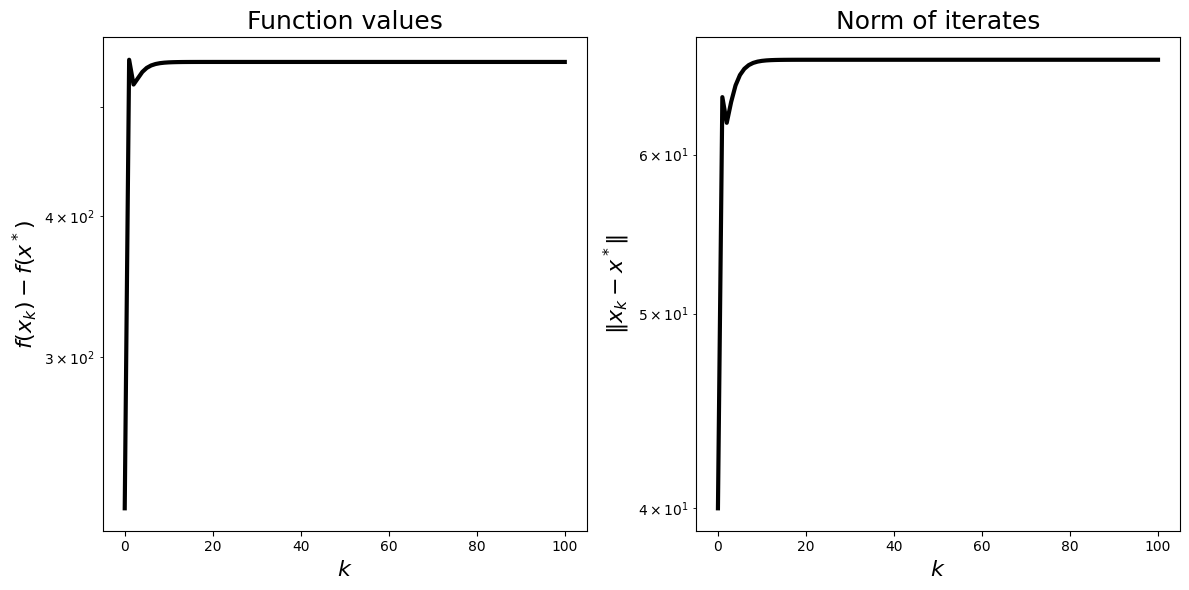

In [ ]:
x_norms = np.square(np.linalg.norm(x_iters, ord=2, axis=1))
plot_fvals(f_vals, x_norms, yscale='log')

plottiamo ora la sequenza $\| x_k - x_{k -1} \|$

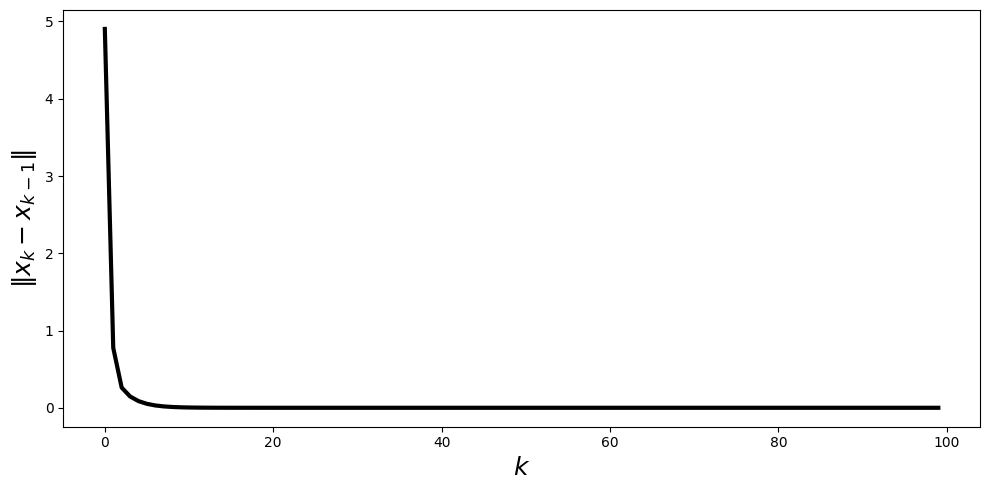

In [ ]:
xk_seq = np.empty(x_iters.shape[0]-1)
for i in range(x_iters.shape[0]-1):
  xk_seq[i] = np.linalg.norm(x_iters[i + 1] - x_iters[i], ord=2)


fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(range(xk_seq.shape[0]), xk_seq, '-', c='black', lw=3)
ax.set_xlabel("$k$", fontsize=18)
ax.set_ylabel("$\| x_k - x_{k - 1} \|$", fontsize=18)
fig.tight_layout()

### [Opzionale] One dimensional deconvolution
Consideriamo l'operatore lineare $\Phi$ definito come segue
$$
(\forall x \in \mathbb{R}^d) \quad \Phi x = h * x
$$
dove $*$ indica la convoluzione. Sia
$$
\bar{h}(t) = (1 - t^2/25) e^{-t^2/50}
$$
definiamo $h(t) = \bar{h}(t) - \mathbb{E}[\bar{h}(t)]$. Ad esempio, consideriamo l'intervallo $[-200, 200]$ e plottiamo il filtro $h$ in funzione di $t$

(-200.0, 200.0)

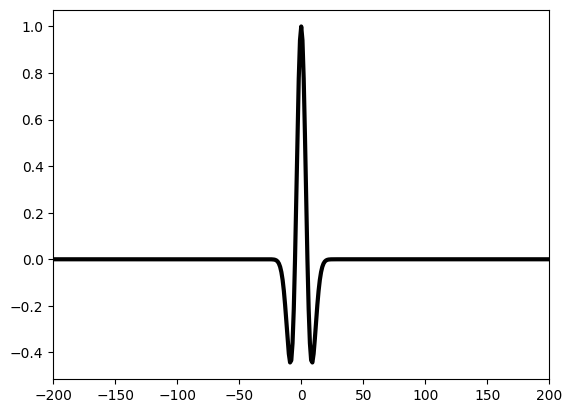

In [ ]:
N = 1024

s = 5

t = np.arange(-N/2,N/2)
h = (1-t**2/s**2)*np.exp(-(t**2)/(2*s**2))
h = h - h.mean()


fig, ax = plt.subplots()
ax.plot(t, h, '-', lw=3, c='black')
ax.set_xlim([-200, 200])

L'operatore di convoluzione invece e` implementabile come prodotto nel dominio delle Fourier transform. Per implementare $\Phi$ quindi dobbiamo trasformare $h$ e $x$ usando le Fourier transform, computare il prodotto e trasformare il risultato usando l'inversa.


In [ ]:
from numpy.fft import fft, fftshift, ifft # package per fast fourier transform
from numpy import real


h_tf = fft(fftshift(h))

def phi(x):
  return real(ifft(fft(x) * h_tf))

Generiamo ora il segnale vero (i.e. quello che dovremo recuperare) e forziamo il segnale ad avere solo $10$ componenti diverse da $0$ con valori tra $[-1, -0.7]$ e $[0.7, 1]$.


In [ ]:
s = round(N*.01) # number of nonzero elements of xsharp
sel = np.random.permutation(N)
sel = sel[0:s]   # indices of the nonzero elements of xsharp
x_bar = np.zeros(N)
x_bar[sel] = np.sign(np.random.randn(s)) * (1-0.3*np.random.rand(s))


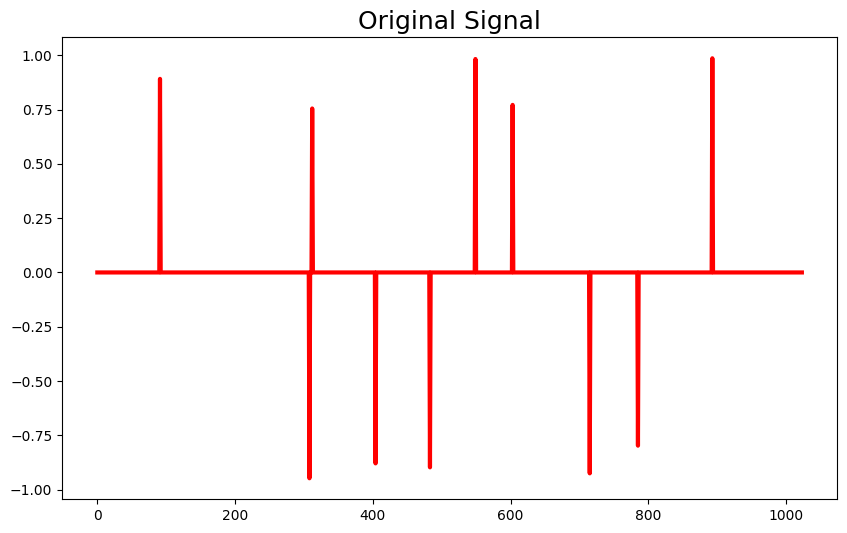

In [ ]:
fig, ax = plt.subplots(figsize=(10,6))
ax.set_title("Original Signal", fontsize=18)
ax.plot(range(N), x_bar, lw=3, c='red')

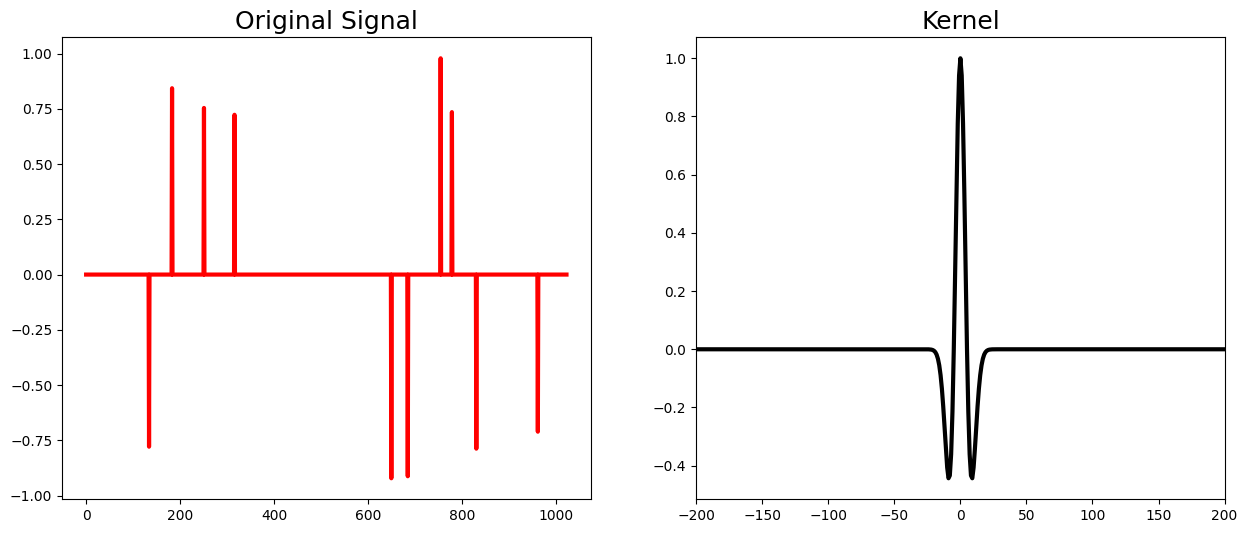

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

N = 1024
s = 5

# Generate some example data for x_bar
x_bar = np.random.normal(0, 1, N)

# Create the time array
t = np.arange(-N/2, N/2)

# Generate the kernel
h = (1 - t**2/s**2) * np.exp(-(t**2)/(2*s**2))
h = h - h.mean()


s = round(N*.01) # number of nonzero elements of xsharp
sel = np.random.permutation(N)
sel = sel[0:s]   # indices of the nonzero elements of xsharp
x_bar = np.zeros(N)
x_bar[sel] = np.sign(np.random.randn(s)) * (1-0.3*np.random.rand(s))


# Create subplots
fig, axs = plt.subplots(1, 2, figsize=(15, 6))

# Plot the original signal in the first subplot
axs[0].plot(range(N), x_bar, lw=3, c='red')
axs[0].set_title("Original Signal", fontsize=18)

# Plot the kernel in the second subplot
axs[1].plot(t, h, '-', lw=3, c='black')
axs[1].set_xlim([-200, 200])
axs[1].set_title("Kernel", fontsize=18)

plt.show()


Aggiungiamo ora del rumore gaussiano con deviazione standard $0.2$ e computiamo l'osservazione come
$$
y = \Phi(x) + \epsilon
$$

In [ ]:
noise_std = 0.2
y = phi(x_bar) + noise_std * rnd_state.randn(N)

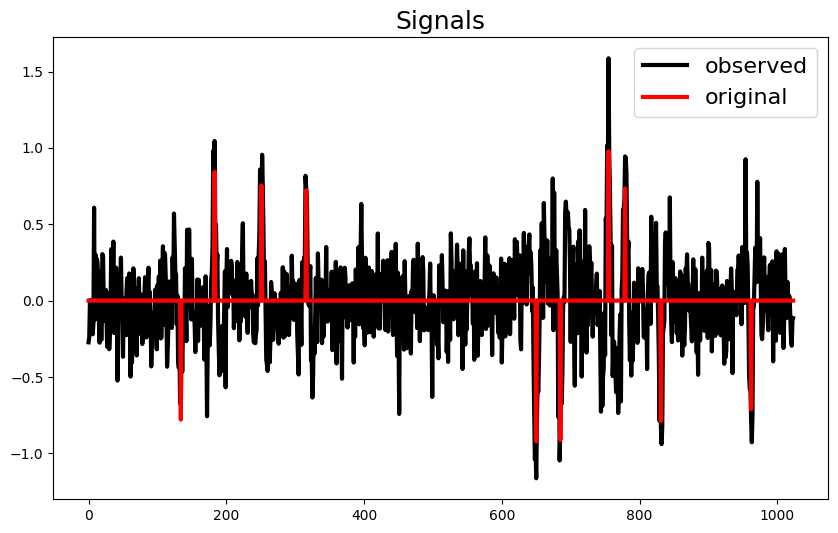

In [ ]:
fig, ax = plt.subplots(figsize=(10,6))
ax.set_title("Signals", fontsize=18)
ax.plot(range(N), y, lw=3, c='black', label='observed')
ax.plot(range(N), x_bar, lw=3, c='red', label='original')
ax.legend(fontsize=16)

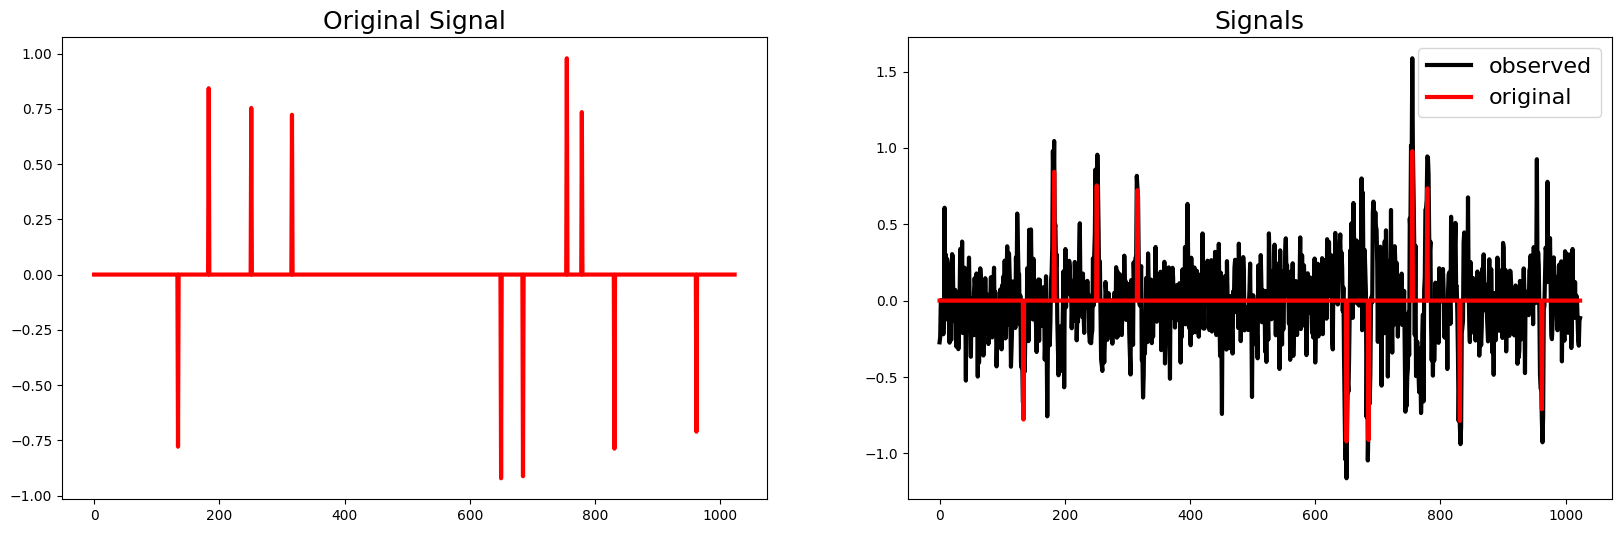

In [ ]:
N = len(x_bar)

fig, axs = plt.subplots(1, 2, figsize=(20, 6))  # Create a single figure with 1 row and 2 columns of subplots

# First subplot
axs[0].set_title("Original Signal", fontsize=18)
axs[0].plot(range(N), x_bar, lw=3, c='red')

# Second subplot
axs[1].set_title("Signals", fontsize=18)
axs[1].plot(range(N), y, lw=3, c='black', label='observed')
axs[1].plot(range(N), x_bar, lw=3, c='red', label='original')
axs[1].legend(fontsize=16)

plt.show()

Per recuperare il segnale original, minimizziamo la seguente funzione
$$
\min F(x) := \underbrace{\frac{1}{2} \| \Phi(x) - y \|_2^2}_{f(x)} + \underbrace{\lambda \| x \|_1}_{g(x)}.
$$
Nota che $f$ e\` differenziabile e (dato che $\Phi(x) = \Phi(x)^\intercal$) il gradiente e\`
$$
\nabla f(x) = \Phi(\Phi(x) - y)
$$
e la costante di Lipschitz e\` calcolabile come segue
```
L = np.max(np.abs(fft(h))) ** 2
```

In [ ]:
def target(x, lam):
  return np.linalg.norm(phi(x) - y, ord=2)**2/2 + lam * np.linalg.norm(x, ord=1)

Implementiamo la funzione `grad_f` che presa una $x$ ritorna il gradiente di $f$ in $x$

In [ ]:
def grad_f(x):
  # TODO: return il gradiente di f in x
  return phi(phi(x)-y)

def prox_g(x, gamma, lam):
  # TODO: return il prox di g in x
  S=[]
  for i in range(len(x)):
    if x[i]> gamma*lam:
      S.append(x[i]-gamma*lam)
    elif x[i]< -gamma*lam:
      S.append(x[i]+gamma*lam)
    else:
      S.append(0)
  return np.array(S)

Implementiamo ora la funzione `pg_descent` che risolve il problema di minimizzazione usando prox-gradient method.

In [ ]:
def pg_descent(x0, gamma, lam, T = 20):
  f_values = np.empty(T + 1)
  x_iters = np.empty((T + 1, x0.shape[0]))
  x = x0.copy()
  f_values[0] = target(x0, lam)
  x_iters[0] = x.copy()
  for t in range(T):
    x = prox_g(x-gamma*grad_f(x), gamma, lam) # TODO: computa l'iterazione di forward-backward
    f_values[t + 1] = target(x, lam) - target(x_bar, lam)
    x_iters[t + 1] = x.copy()
  return x, f_values, x_iters

Eseguiamo l'algoritmo

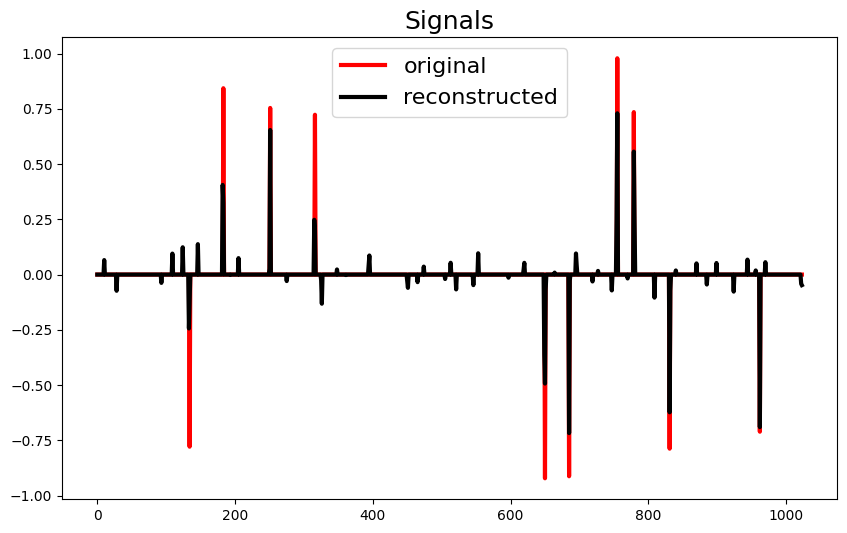

In [ ]:
x0 = np.full(N, 1.0) # guess iniziale
lam = 0.5
T = 5000

L = np.max(np.abs(fft(h))) ** 2
gamma =1/L # TODO: fissa uno stepsize ragionevole


# TODO: esegui l'algoritmo
x, f_vals, x_iters =pg_descent(x0, gamma, lam, T)

# Plottiamo il segnale originale e la ricostruzione
fig, ax = plt.subplots(figsize=(10,6))
ax.set_title("Signals", fontsize=18)
ax.plot(range(N), x_bar, lw=3, c='red', label='original')
ax.plot(range(N), x, lw=3, c='black', label='reconstructed')
ax.legend(fontsize=16)

Plottiamo ora la sequenza
$$
\| x_k - x^* \|
$$

Text(0, 0.5, '$\\| x_k - x^* \\|$')

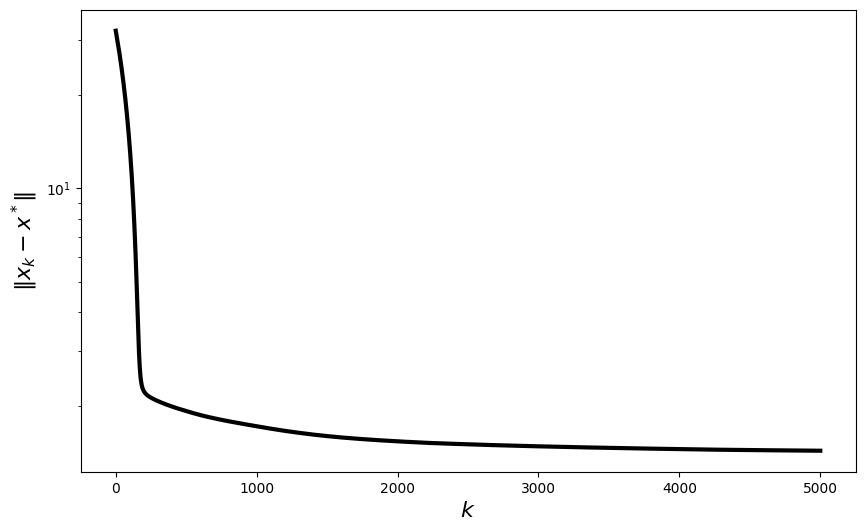

In [ ]:
x_norms = np.linalg.norm(x_iters - x_bar, axis=1, ord=2)

fig, ax = plt.subplots(figsize=(10,6))
ax.plot(range(x_norms.shape[0]), x_norms, '-', lw=3, c='black')
ax.set_yscale("log")
ax.set_xlabel("$k$", fontsize=16)
ax.set_ylabel("$\| x_k - x^* \|$", fontsize=16)

Prova diversi valori per $\lambda$ e osserva come varia la ricostruzione e la sequenza $\| x_k - x^* \|$

In [ ]:
lams = [1e-2, 1e-1, 0.5, 1.0, 3.0, 5.0]

x_iters = []
x0 = np.full(N, 1.0) # guess iniziale
T = 5000

L = np.max(np.abs(fft(h))) ** 2
gamma =1/L # TODO: fissa uno stepsize ragionevole

for lam in lams:
  _, _, xs =pg_descent(x0, gamma, lam, T)# TODO: esegui l'algoritmo
  x_iters.append(xs)


Plottiamo le sequenza ottenute

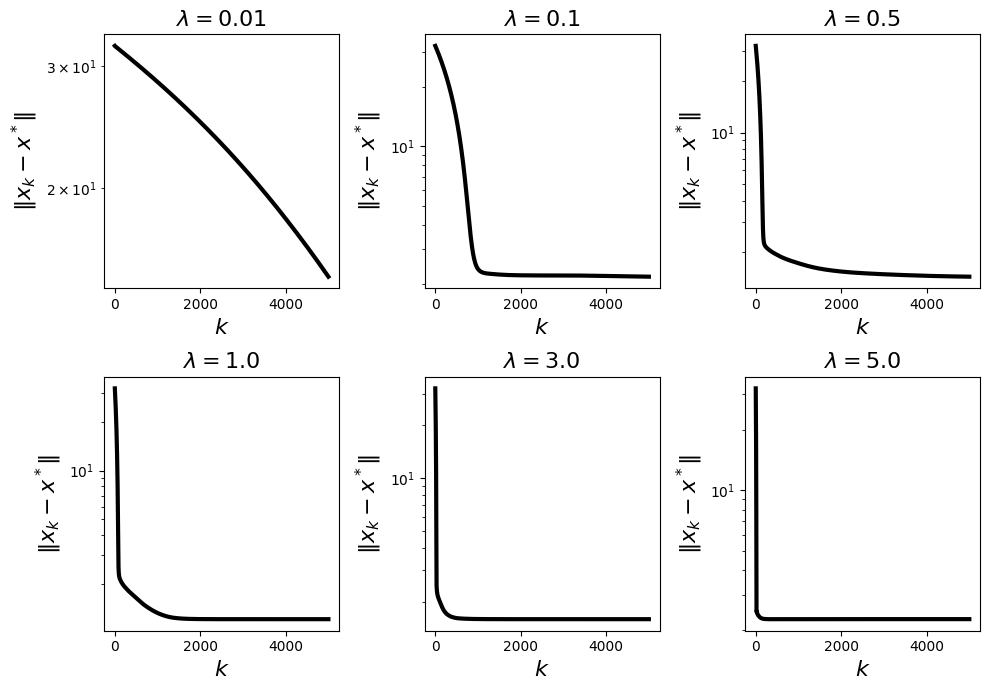

In [ ]:
lams = [1e-2, 1e-1, 0.5, 1.0, 3.0, 5.0]

c = 0
fig, axs = plt.subplots(2, 3, figsize=(10, 7))

for i in range(axs.shape[0]):
    for j in range(axs.shape[1]):
        x_norms = np.linalg.norm(x_iters[c] - x_bar, ord=2, axis=1)
        axs[i, j].plot(x_norms, '-', c='black', lw=3)
        axs[i, j].set_yscale("log")
        axs[i, j].set_ylabel("$\| x_k - x^* \|$", fontsize=16)
        axs[i, j].set_xlabel("$k$", fontsize=16)
        axs[i, j].set_title(f"$\lambda = {lams[c]}$", fontsize=16)
        c += 1

fig.tight_layout()

plt.show()

Plottiamo le diverse ricostruzioni

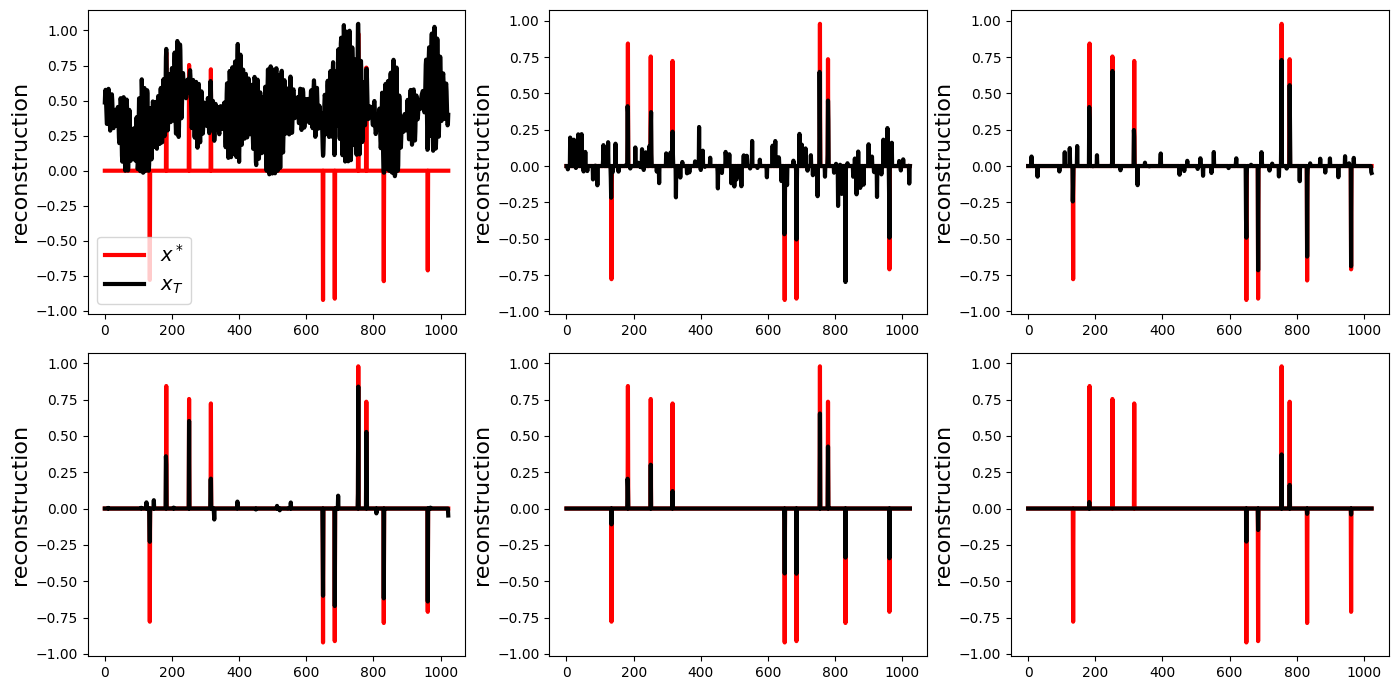

In [ ]:
c = 0
fig, axs = plt.subplots(2, 3, figsize=(14, 7))
for i in range(axs.shape[0]):
  for j in range(axs.shape[1]):
    axs[i, j].plot(x_bar, '-', c='red', lw=3, label='$x^*$')
    axs[i, j].plot(x_iters[c][-1], '-', c='black', lw=3, label='$x_T$')
    axs[i, j].set_ylabel("reconstruction", fontsize=16)
    if c == 0:
      axs[i, j].legend(fontsize=14)
    c+=1

fig.tight_layout()



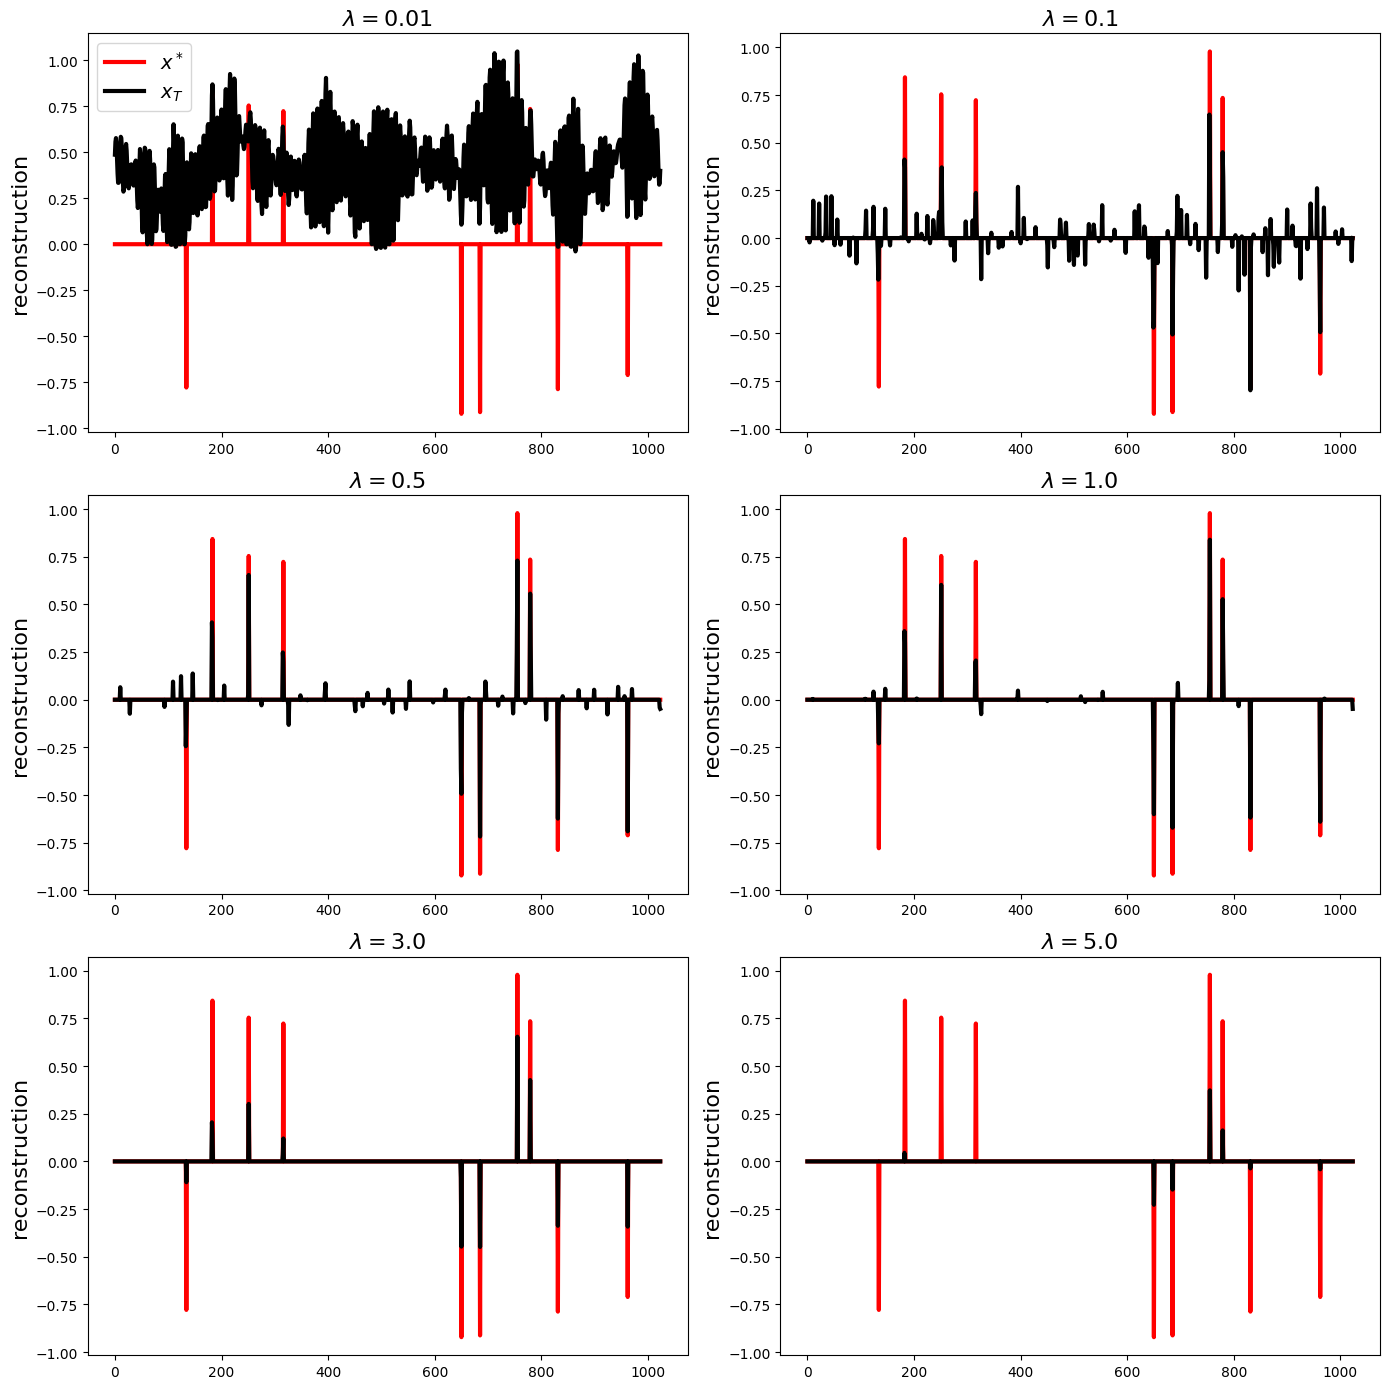

In [ ]:
lams = [1e-2, 1e-1, 0.5, 1.0, 3.0, 5.0]
c = 0
fig, axs = plt.subplots(3, 2, figsize=(14, 14))

for i in range(axs.shape[0]):
    for j in range(axs.shape[1]):
        axs[i, j].plot(x_bar, '-', c='red', lw=3, label='$x^*$')
        axs[i, j].plot(x_iters[c][-1], '-', c='black', lw=3, label='$x_T$')
        axs[i, j].set_ylabel("reconstruction", fontsize=16)
        axs[i, j].set_title(f"$\lambda = {lams[c]}$", fontsize=16)
        if c == 0:
            axs[i, j].legend(fontsize=14)
        c += 1

fig.tight_layout()

plt.show()

## Acceleration
Sia $\bar{x} \in \mathbb{R}^d$ e $A \in \mathbb{R}^{n \times d}$ con $A_{i,j} \sim \mathcal{N}(0, 1)$ per ogni $i,j$.

Definiamo $y = A\bar{x}$ e consideriamo il seguente problema di ottimizzazione
$$
\min\limits_{x \in \mathbb{R}^d} F(x) := \frac{1}{2} \| Ax - y \|^2.
$$
Nello specifico, consideriamo $n = 100$ e $d =50$.



In [ ]:
n = 100
d = 50
A = rnd_state.randn(n, d)

x_bar = np.ones(d)

y = A @ x_bar

def F1(x):
  return 1/2 * np.square(np.linalg.norm(A @ x - y, ord=2))

Dato che la funzione e\` smooth e convessa possiamo usare gradient descent per risolvere il problema.
Definiamo quindi una funzione
```
grad_f1(x)
```
che preso un punto $x \in \mathbb{R}^d$ ritorna $\nabla F(x)$.

In [ ]:
def grad_f1(x):
  # TODO: ritorna gradiente di F in x
  return np.transpose(A) @ ((A @ x) - y)

e implementiamo una funzione
```
gradient_descent(x0, gamma, T)
```
che preso un punto iniziale $x_0 \in \mathbb{R}^d$, uno step-size $\gamma > 0$ e un numero di iterazioni $T > 0$, ritorna:
- `x`: l'ultima iterata
- `x_iters` : un vettore contenente tutte le iterate
- `f_vals` : un vettore contenente i valori della funzione in ogni iterata

In [ ]:
def gradient_descent(x0, gamma, T):
  x_iters = np.empty((T + 1, x0.shape[0]))
  f_vals = np.empty((T + 1))

  x = x0.copy()
  x_iters[0] = x0.copy()
  f_vals[0] = F1(x0)
  for k in range(T):
    x = x - gamma * grad_f1(x)
    x_iters[k + 1] = x.copy()
    f_vals[k + 1] = F1(x)
  return x, x_iters, f_vals

Eseguiamo ora gradient descent

In [ ]:
#gamma = ... # TODO: scegli uno stepsize appropriato (i.e. l'ottimale)

AtA=np.dot(np.transpose(A),A)
eigenvalues=np.linalg.eigvalsh(AtA)
mu=np.min(eigenvalues)
L=np.max(eigenvalues)
gamma=2/(L+mu)

x0 = np.full(d, -100)
T= 1000

x, gd_iters, gd_vals = gradient_descent(x0, gamma, T)

Definiamo una funzione per plottare i risultati

In [ ]:
# funzioni per plottare i risultati
def plot_ls_results(labels, x_iters, f_vals, x_bar):
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
  for i in range(len(labels)):
    x_norms = np.linalg.norm(x_iters[i] - x_bar, ord=2, axis=1)
    ax1.plot(range(f_vals[i].shape[0]), f_vals[i], '-', lw=3, label='{}'.format(labels[i]))
    ax2.plot(range(x_norms.shape[0]), x_norms, '-', lw=3)

  ax1.set_ylabel("$F(x_k) - F(\\bar{x})$", fontsize=16)
  ax2.set_ylabel("$\| x_k - \\bar{x}\|$", fontsize=16)
  ax1.set_xlabel("$k$", fontsize=16)
  ax2.set_xlabel("$k$", fontsize=16)


  ax1.set_yscale("log")
  ax2.set_yscale("log")


  ax1.legend(fontsize=12)

  fig.tight_layout()

Plottiamo le sequenze $\| x_k - \bar{x}\|$ e $F(x_k) - F(x^*)$

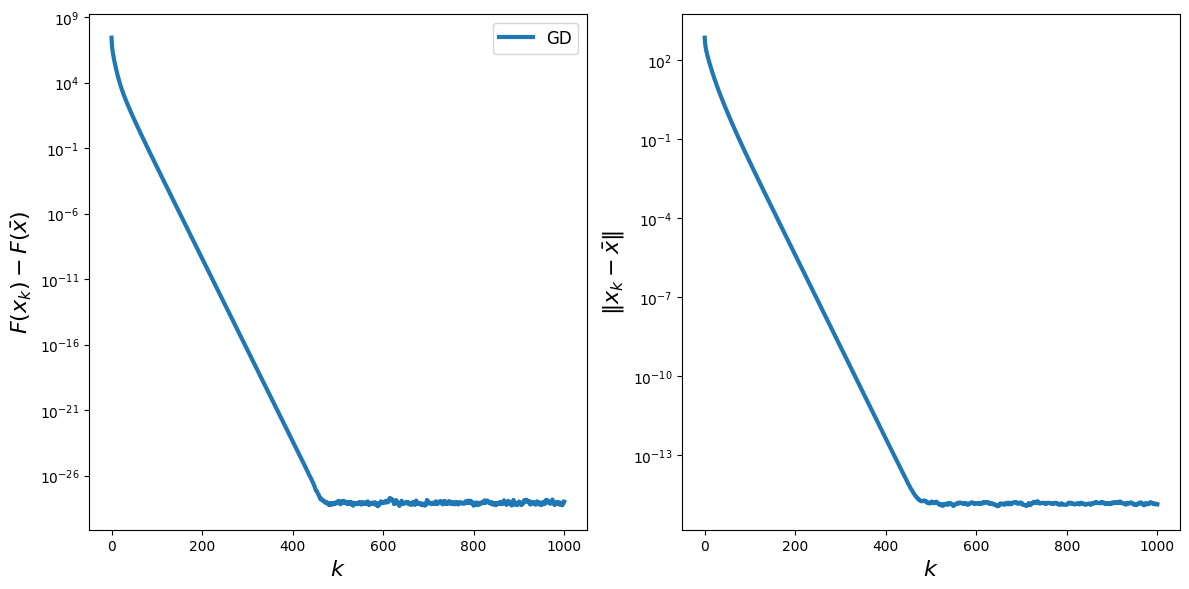

In [ ]:
plot_ls_results(['GD'], [gd_iters], [gd_vals], x_bar)

### Nesterov acceleration
Un modo per ottenere accelerazione, consiste nell'aggiungere un termine di inerzia che contiene l'informazione delle precedenti iterate. Quest'idea puo\` essere implementata con il seguente algoritmo noto come "Nesterov accelerated Gradient" (NAG): dato $x_0 \in \mathbb{R}^d$, sia $y_0 = x_0$, allora
$$
\left\{\begin{array}{l}
x_{k + 1} = y_k - \gamma \nabla f(y_k)\\
y_{k + 1} = x_{k + 1} + \beta_{k + 1} (x_{k + 1} - x_k)
\end{array}
\right.
$$
Dove $\beta_{k} \geq 0$ e\` il parametro d'inerzia.

Nota che l'algoritmo puo\` essere riscritto come segue
$$
x_{k + 1} = x_{k} + \beta_{k} (x_{k} - x_{k - 1}) - \gamma \nabla f(x_{k} + \beta_{k} (x_{k} - x_{k-1})).
$$
Inoltre con $\beta_k = 0$ (per ogni $k$), recuperiamo gradient descent.



#### Inerzia
Nel caso di funzioni fortemente convesse, la scelta dei parametri (inerzia e step-size) migliore e\`
$$
\gamma = \frac{1}{L} \qquad \text{e}\qquad \beta_k = \frac{\sqrt{L} - \sqrt{\mu}}{\sqrt{L} + \sqrt{\mu}}
$$



Implementiamo ora l'algoritmo NAG mediante la funzione
```
nag(x0, gamma, beta, T)
```
Dove:
- `x0`: il punto iniziale.
- `gamma`: lo step-size.
- `beta`: parametro d'inerzia.
- `T` : numero di iterazioni.

La funzione deve ritornare:
- `x`: l'ultima iterata.
- `x_iters` : un vettore contenente tutte le iterate.
- `f_vals` : un vettore contenente i valori della funzione in ogni iterata.

In [ ]:
def nag(x0,  gamma, beta, T):
  x = x0.copy()
  y = x0.copy()

  x_iters = np.empty((T + 1, x0.shape[0]))
  f_vals = np.empty((T + 1))

  x_iters[0] = x.copy()
  f_vals[0] = F1(x)

  tk = 1
  for k in range(T):

    # TODO: computa l'iterazione di NAG
    x_next = y-gamma*grad_f1(y) # calcola x_{k + 1}
    y_next = x_next+beta*(x_next-x) # calcola y_{k + 1}


    x = x_next
    y = y_next
    x_iters[k + 1] = x.copy()
    f_vals[k + 1] = F1(x)
  return x, x_iters, f_vals

Eseguiamo ora NAG e confrontiamo i risultati con gradient descent.


In [ ]:
#gamma =  ... # TODO: scegli uno stepsize appropriato

AtA=np.dot(np.transpose(A),A)
eigenvalues=np.linalg.eigvalsh(AtA)
mu=np.min(eigenvalues)
L=np.max(eigenvalues)
gamma=1/(L)

beta = (np.sqrt(L)-np.sqrt(mu))/(np.sqrt(L)+np.sqrt(mu))# TODO: scegli il parametro d'inerzia

x0 = np.full(d, -100)
T= 1000

x, nag_iters, nag_vals = nag(x0, gamma, beta, T)
x, gd_iters, gd_vals = gradient_descent(x0, 2/(L+mu), T)

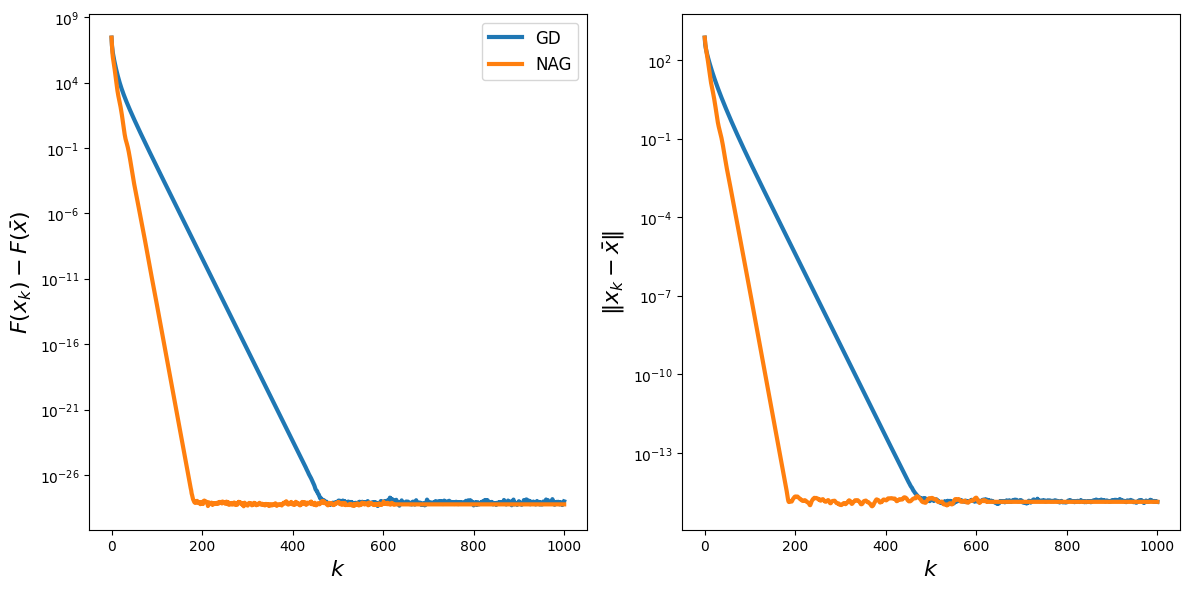

In [ ]:
labels = ["GD", "NAG"]
x_iters = [gd_iters , nag_iters]
f_vals = [gd_vals, nag_vals]

plot_ls_results(labels, x_iters, f_vals, x_bar)

### Heavy-ball method
Un algoritmo alternativo per ottenere accellerazione, consiste nell'includere l'inerzia solo nell'estrapolazione (i.e. non nel gradiente). Dato $x_0 \in \mathbb{R}^d$,
$$
x_{k + 1} = x_k  - \gamma \nabla f(x_k) + \underbrace{\beta_k (x_{k} - x_{k - 1})}_{\text{momentum}}
$$

Implementiamo quindi la funzione
```
hb(x0, F, grad_f, gamma, beta, T = 20)
```
dove:
- `x0`: e\` il punto iniziale
- `F`: la funzione target
- `grad_f`: funzione che data $x$ ritorna $\nabla F(x)$
- `gamma` e\` lo stepsize
- `beta` e\` il parametro inerziale
- `T` e\` il numero di iterazioni

In [ ]:
def hb(x0, gamma, beta, T = 20):
  f_values = np.empty(T + 1)
  x_iters = np.empty((T + 1, x0.shape[0]))
  x = x0.copy()
  x_prev = x0.copy()
  f_values[0] = F1(x)
  x_iters[0] = x.copy()
  momentum = 0
  for t in range(T):

    # TODO: computa l'iterazione di Heavy-ball
    if t>0:
      momentum=beta*(x-x_iters[t-1])
      x = x-gamma*grad_f1(x)+momentum

    f_values[t + 1] = F1(x)
    x_iters[t + 1] = x.copy()
  return x, x_iters, f_values

Come visto a lezione, scegliendo
$$
\gamma = \frac{4}{(\sqrt{L} + \sqrt{\mu})^2} \qquad \text{e} \qquad \beta = \Bigg( \frac{\sqrt{L} - \sqrt{\mu}}{\sqrt{L} + \sqrt{\mu}} \Bigg)^2
$$
si ottiene un rate migliore di GD.

Eseguiamo quindi Heavy-ball e confrontiamo il risultato con NAG e GD (ottenuti precedentemente)


In [ ]:
gamma = 4/pow((np.sqrt(L)+np.sqrt(mu)),2) # TODO: scegli uno stepsize appropriato

beta = pow((np.sqrt(L)-np.sqrt(mu))/(np.sqrt(L)+np.sqrt(mu)),2) # TODO: scegli un parametro d'inerzia appropriato

x0 = np.full(d, -100)
T= 1000

x, hb_iters, hb_vals = hb(x0, gamma, beta, T)

Plottiamo ora i risultati

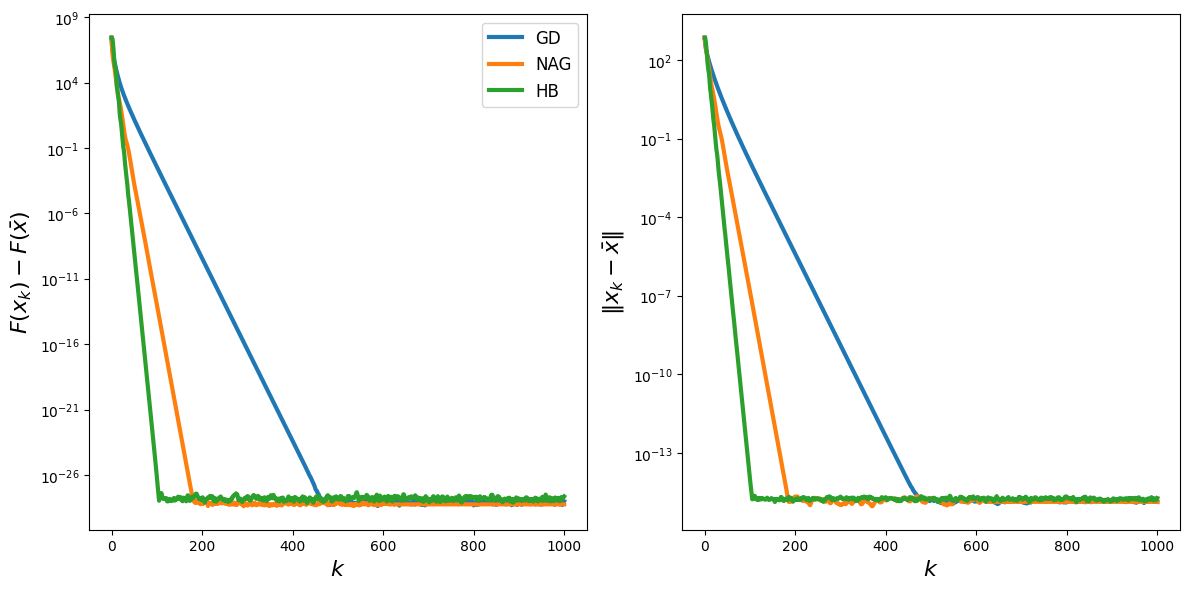

In [ ]:
labels = ["GD", "NAG", "HB"]
x_iters = [gd_iters, nag_iters, hb_iters]
f_vals = [gd_vals, nag_vals, hb_vals]

plot_ls_results(labels, x_iters, f_vals, x_bar)

## Signal Reconstruction (Lasso)
Sia
$$
y = A \bar{x}
$$
dove:
- $A \in \mathbb{R}^{n \times d}$ e\` una matrice che modella un processo di acquisizione.
- $\bar{x} \in \mathbb{R}^d$ e\` un qualche segnale.
- $y \in \mathbb{R}^n$

Consideriamo ad esempio $n = 1000$, $d = 500$. Inoltre assumiamo $A_{i,j} \sim \mathcal{N}(0,1)$ e che le osservazioni siano con rumore gaussiane
$$
\tilde{y} = y + \epsilon
$$
con $\epsilon_i \sim \mathcal{N}(0, 1)$.




In [ ]:
n = 1000
d = 500

A = rnd_state.randn(n, d) # matrice A
x_bar = rnd_state.randn(d) # segnale da recuperare
y = A @ x_bar + np.sqrt(0.1) * rnd_state.randn(n) # osservazione con noise




Consideriamo il problema di recuperare il segnale $\bar{x}$. Per far cio\` consideriamo il seguente problema
$$
\min\limits_{x \in \mathbb{R}^d} \underbrace{\frac{1}{2} \| Ax - y \|^2}_{=: f(x)} + \underbrace{\lambda \| x \|_1}_{=: g(x)}
$$

Dato che la funzione $g$ e\` non liscia, non possiamo usare gradient descent per risolvere il problema.


In [ ]:
# per semplicita` supponiamo di conoscere un "buon" valore per lambda
lam = 0.1

# definiamo la target function
def F2(x):
  return 1/2 * np.square(np.linalg.norm(A @ x - y , ord=2)) + lam * np.linalg.norm(x, ord=1)


Come possiamo osservare, il problema e\` della forma $F(x) = f(x) + g(x)$ dove $f$ e\` liscia e con gradiente $L$ smooth. Dove la costante $L = \| A^\intercal A \|$.

Implementiamo, quindi, la funzione `grad_f2` che presa una `x` ritorna il gradiente di $f$ in $x$.


In [ ]:
def grad_f2(x):
  return A.T @ (A @ x - y)

Nelle lezioni precedenti, abbiamo introdotto e implementato subgradient descent che permette di affrontare questo tipo di problemi:
___
**Subgradient Descent:**
$$
x_{k + 1} = x_k - \gamma_k g_k \qquad \text{con} \qquad g_k \in \partial f(x_k)
$$


Di seguito, proponiamo un implementazione di Subgradient descent

In [ ]:
# Funzione che ritorna un sottogradiente
def sample_subgrad(x):
  grd = grad_f2(x)
  sgn = lam * np.sign(x)
  return grd + sgn

# subgradient descent
def subgrad_descent(x0, gamma_0, T = 20):
  # NOTA CHE il passo e` della forma gamma/sqrt(t)
  # quindi il gamma passato e` la costante
  f_values = np.empty(T + 1)
  x_iters = np.empty((T + 1, x0.shape[0]))
  x = x0.copy()
  f_values[0] = F2(x)
  x_iters[0] = x.copy()
  for t in range(T):
    gamma_k = gamma_0 / np.sqrt(t + 1)
    g = sample_subgrad(x)
    x = x - gamma_k * g
    f_values[t + 1] = F2(x)
    x_iters[t + 1] = x.copy()
  return x, f_values, x_iters

Come abbiamo potuto osservare nella teoria, l'algoritmo non ha buoni rate di convergenza.

### Forward-backward

Tuttavia, nonostante la funzione $g$ non sia liscia, e\` possibile calcolare il proximity operator in forma chiusa
$$
(\text{prox}_{\lambda g}(x))_i = \left\{
  \begin{array}{ll}
    x_i - \gamma \lambda & \text{if} \,\, x_i > \gamma \lambda\\
    0 & \text{if} \,\, |x_i| \leq \gamma \lambda\\
    x_i + \gamma \lambda & \text{if} \,\, x_i < -\gamma \lambda
  \end{array}
  \right.
$$
Implementa la funzione `prox_g` definita come segue
```
prox_g(x, gamma, lam)
```
dove:
- `x` e\` un numpy array
- `gamma` e\` lo step-size
- `lam` e\` il parametro di regolarizzazione

Fissando $\gamma$ e $\lambda$ possiamo plottare la funzione prox

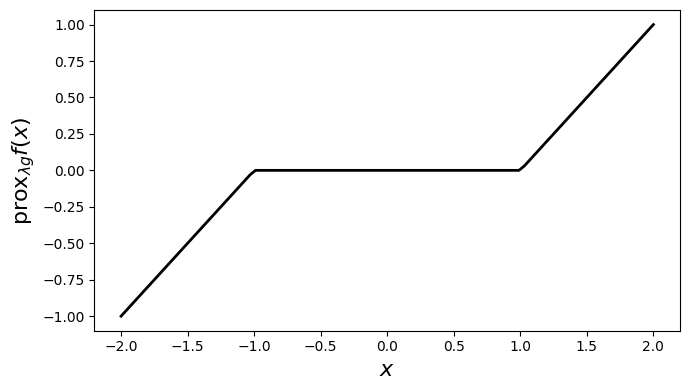

In [ ]:
gamma = 1.0
lam = 1.0

X = np.linspace(-2 * gamma * lam, 2 * gamma * lam, 100)
X_prox = prox_g(X, gamma, lam)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(X, X_prox, '-', c='black', lw=2)
ax.set_xlabel("$x$", fontsize=16)
ax.set_ylabel('prox$_{\lambda g} f(x)$', fontsize=16)
fig.tight_layout()

Dato che possiamo calcolare il prox, possiamo implementare l'algoritmo forward-backward

___
**Forward-backward:**
$$
x_{k+1} = \text{prox}_{\lambda g}(x_k - \gamma \nabla f(x_k))
$$
dove il prox operator e\` definito come segue
$$
\text{prox}_{\lambda f}(v) := \arg \min\limits_{x \in \mathbb{R}^d} \Big\{ f(x) + \frac{1}{2 \lambda} \| x - v \|^2 \Big\}.
$$
___

In [ ]:
# Implementazione di Forward-Backward
def prox_grad(x0, gamma, T = 20):
  f_values = np.empty(T + 1)
  x_iters = np.empty((T + 1, x0.shape[0]))
  x = x0.copy()
  f_values[0] = F2(x)
  x_iters[0] = x.copy()
  for t in range(T):
    # TODO: implementa l'iterazione di forward-backward
    x = prox_g(x-gamma*grad_f2(x), gamma, lam)
    f_values[t + 1] = F2(x)
    x_iters[t + 1] = x.copy()
  return x, f_values, x_iters


Eseguiamo quindi i due algoritmi fissandone i parametri

In [ ]:
x0 = np.full(d, 50) # guess iniziale
T = 400

AtA=np.dot(np.transpose(A),A)
L=np.linalg.norm(AtA)
gamma =1/L # TODO: fissa uno stepsize ragionevole

F_star = F2(x_bar)

_, sg_fvals, sg_x_iters = subgrad_descent(x0, gamma, T) # TODO: esegui l'algoritmo subgradient descent
_, pg_fvals, pg_x_iters = prox_grad(x0, gamma, T ) # TODO: esegui l'algoritmo  forward-backward

sg_fvals -= F2(x_bar)
pg_fvals -= F2(x_bar)

Confrontando subgradient descent e forward-backward possiamo osservare che quest'ultimo ottiene performance migliori

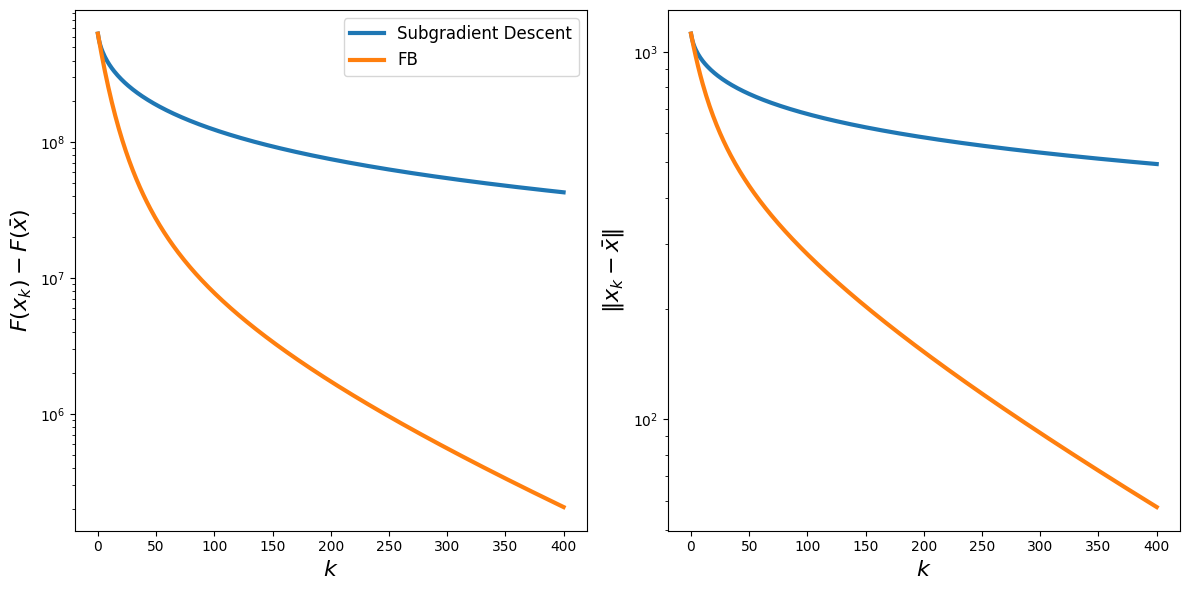

In [ ]:
labels = ['Subgradient Descent', 'FB']

x_iters = [sg_x_iters, pg_x_iters]
f_vals = [sg_fvals, pg_fvals]

plot_ls_results(labels, x_iters, f_vals, x_bar)


### Heavy-ball
Possiamo estendere heavy-ball includendo il prox. Dato $x_0 \in \mathbb{R}^d$,
$$
x_{k + 1} = \text{prox}_{\gamma g}(x_k + \beta_k (x_{k} - x_{k - 1}) - \gamma \nabla f(x_k))
$$
Nota che per $\beta_k = 0$, l'algoritmo e\` identico a proximal gradient.


In [ ]:
def heavy_ball(x0, gamma, beta, T = 20):
  f_values = np.empty(T + 1)
  x_iters = np.empty((T + 1, x0.shape[0]))
  x = x0.copy()
  x_prev = x0.copy()
  f_values[0] = F2(x)
  x_iters[0] = x.copy()
  momentum = 0
  for t in range(T):
    # TODO: computa l'iterazione di prox-Heavy-ball
    if t>0:
      momentum=beta*(x-x_iters[t-1])
    x =prox_g(x-gamma*grad_f2(x)+momentum, gamma, lam)
    f_values[t + 1] = F2(x)
    x_iters[t + 1] = x.copy()
  return x, f_values, x_iters

Esegui HB con diversi valori di $\beta \in (0, 1)$ e compara le prestazioni con subgradient method e forward-backward

In [ ]:

betas = [ 0.1, 0.5, 0.9, 0.88, 1 ]

hb_iters = []
hb_vals = []

for beta in betas:
  _, hb_fvals, hb_x_iters = heavy_ball(x0, gamma, beta, T = T)
  hb_iters.append(hb_x_iters)
  hb_vals.append(hb_fvals - F_star)



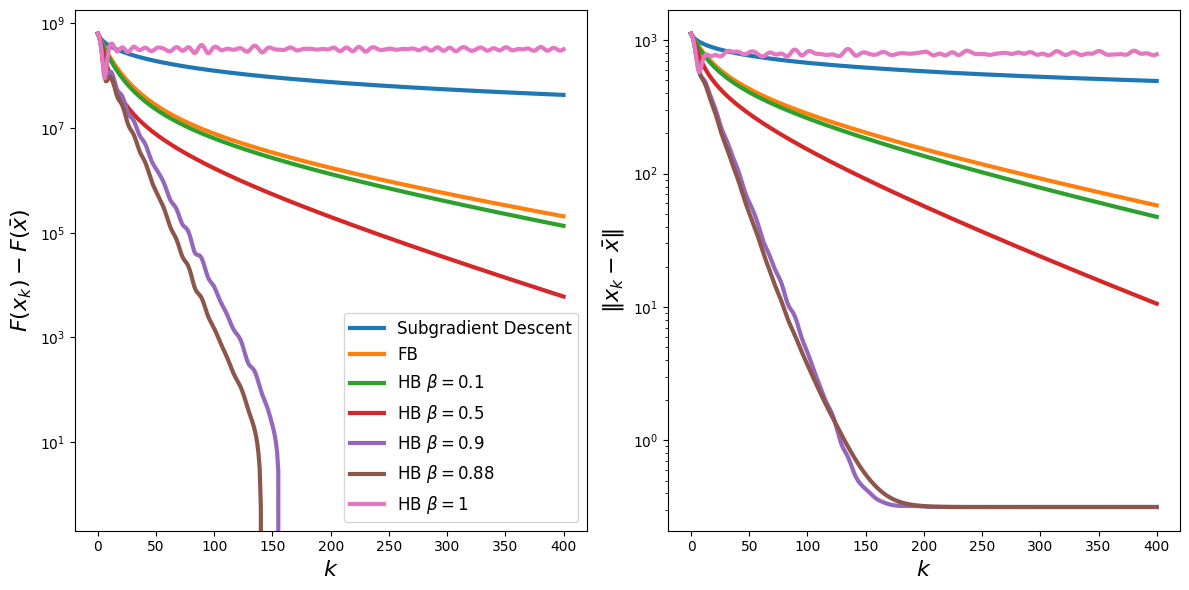

In [ ]:
labels = ['Subgradient Descent', 'FB'] + ['HB $\\beta = {}$'.format(beta) for beta in betas]

x_iters = [sg_x_iters, pg_x_iters] + hb_iters
f_vals = [sg_fvals, pg_fvals] + hb_vals

plot_ls_results(labels, x_iters, f_vals, x_bar)


### Nesterov Acceleration: FISTA
Possiamo estendere anche NAG includendo il prox. L'algoritmo ottenuto prende il nome di "Fast Iterative Soft Thresholding Algorithm"(FISTA).
$$
\left\{\begin{array}{l}
x_{k + 1} = \text{prox}_{\lambda,g}(y_k - \gamma \nabla f(y_k))\\
y_{k + 1} = x_{k + 1} + \beta_{k + 1} (x_{k + 1} - x_k)
\end{array}
\right.
$$



**Inerzia**

In letteratura, diversi parametri di inerzia sono stati proposti. Nello specifico, il parametro $\beta_k$ e\` generalmente scelto come
$$
\beta_{k + 1} = \frac{t_k - 1}{t_{k + 1}}
$$
dove $t_k$ e\` una sequenza che (al fine di ottenere accelerazione) deve soddisfare la seguente condizione
$$
t_{k + 1}^2 - t_{k + 1} - t_k^2 \leq 0
$$
In particolare, in questo laboratorio, ne considereremo due:
- Nesterov (Beck & Teboulle): sia $t_0 = 1$ e
$$
t_{k + 1} = \frac{1 + \sqrt{1 + 4 t_k^2}}{2}
$$
- Chambolle & Dossal: sia $t_0 = 1$ e
$$
t_{k + 1} = \frac{k + \alpha}{\alpha}
$$
con $\alpha \geq 2$.

Nota che la condizione per l'accelerazione e\` soddisfatta (come uguaglianza) nel caso di Nesterov ed e\` soddisfatta con la proposta di Chambolle se $\alpha \geq 2$. Inoltre le due proposte sono "equivalenti" per $\alpha = 2$.

Definiamo quindi due funzioni che implementano gli schemi proposti:
- `get_beta_nest`: prende in input $t_k$ e $k$ e ritorna $\beta_{k}$ e $t_{k + 1}$ usando la sequenza di Nesterov.
- `get_beta_chamb`: prende in input $\alpha > 0$ e restituisce una funzione che che prende in input $t_k$ e $k$ e ritorna $\beta_k$ e $t_{k + 1}$ usando la seconda strategia.


In [ ]:
def get_beta_nest(tk, k):
  # TODO: ritorna beta_k usando la sequenza di Nesterov
  t_next = 0.5* (1+np.sqrt(1+4*pow(tk,2))) # calcola t_{k + 1}
  beta = (tk-1)/t_next # calcola beta_{k + 1}
  return beta, t_next

def get_beta_chamb(alpha):
  def get_beta(tk, k):
    # TODO: ritorna beta_{k+1} usando la sequenza di Chambolle-Dossal
    t_next = (k+alpha)/alpha # calcola t_{k + 1}
    beta = (tk-1)/t_next # calcola beta_{k + 1}
    return beta, t_next
  return get_beta



Implementiamo la funzione `fista` che computa l'iterazione proposta. Tale funzione prendera\` i seguenti parametri:
```
fista(x0, gamma, compute_beta, T)
```
Dove:
- `x0`: il punto iniziale.
- `gamma`: lo step-size.
- `compute_beta`: funzione che computa il parametro d'inerzia.
- `T` : numero di iterazioni.

La funzione deve ritornare:
- `x`: l'ultima iterata.
- `x_iters` : un vettore contenente tutte le iterate.
- `f_vals` : un vettore contenente i valori della funzione in ogni iterata.



In [ ]:
def fista(x0, gamma, compute_beta, T):
  x = x0.copy()
  y = x0.copy()

  x_iters = np.empty((T + 1, x0.shape[0]))
  f_vals = np.empty((T + 1))

  x_iters[0] = x.copy()
  f_vals[0] = F2(x)

  tk = 1
  for k in range(T):

    beta_k, t_next = compute_beta(tk, k)

    # TODO: computa l'iterazione di FISTA
    x_next = prox_g(y-gamma*grad_f2(y), gamma, lam) # calcola x_{k + 1}
    y_next = x_next+beta_k*(x_next-x)  # calcola y_{k + 1}

    tk = t_next

    x = x_next
    y = y_next
    x_iters[k + 1] = x.copy()
    f_vals[k + 1] = F2(x)
  return x, x_iters, f_vals

Confrontiamo ora FISTA con subgradient method e forward-backward considerando entrambi gli schemi per il parametro d'inerzia (Nesterov, Chambolle & Dossal) e utilizzando diversi valori per $\alpha$.


In [ ]:
# TODO: esegui fista con beta calcolato con Nesterov method
_, nest_x_iters, nest_fvals = fista(x0, gamma, get_beta_nest, T)
nest_fvals -= F_star


alphas = [2, 2.5, 3, 5, 10, 20] # TODO: Fissa una lista di alpha

ch_iters = []
ch_vals = []

for alpha in alphas:
  # TODO: esegui fista con beta calcolato con Chambolle & Dossal method
  _, ch_x_iters, ch_fvals = fista(x0, gamma, get_beta_chamb(alpha), T)
  ch_iters.append(ch_x_iters)
  ch_vals.append(ch_fvals - F_star)



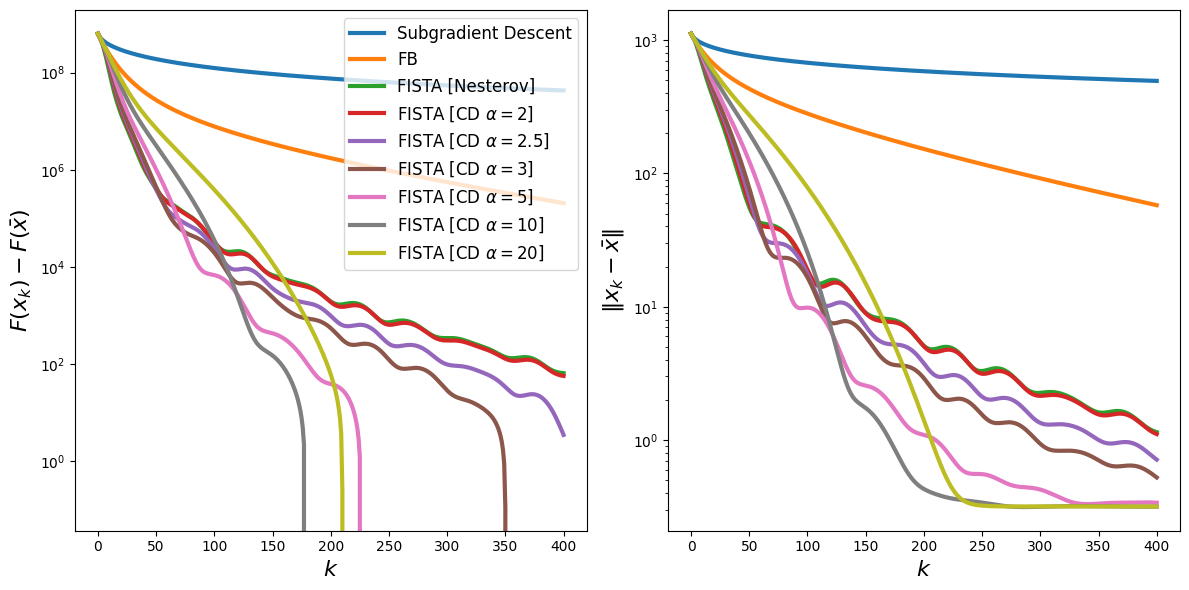

In [ ]:
labels = ['Subgradient Descent', 'FB', 'FISTA [Nesterov]'] + ['FISTA [CD $\\alpha = {}$]'.format(alpha) for alpha in alphas]
x_iters = [sg_x_iters, pg_x_iters, nest_x_iters] + ch_iters
f_vals = [sg_fvals, pg_fvals, nest_fvals] + ch_vals

plot_ls_results(labels, x_iters, f_vals, x_bar)


Plot Nesterov + best HB

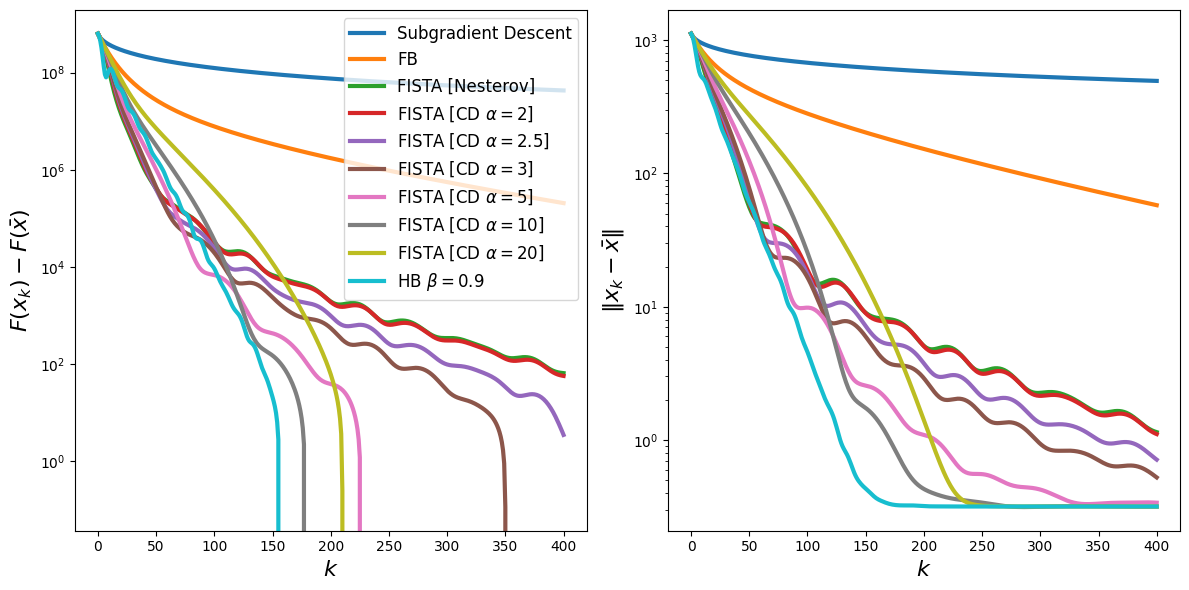

In [ ]:
beta = 0.9

hb_iters = []
hb_vals = []

_, hb_fvals, hb_x_iters = heavy_ball(x0, gamma, beta, T = T)
hb_iters.append(hb_x_iters)
hb_vals.append(hb_fvals - F_star)



# TODO: esegui fista con beta calcolato con Nesterov method
_, nest_x_iters, nest_fvals = fista(x0, gamma, get_beta_nest, T)
nest_fvals -= F_star


alphas = [2, 2.5, 3, 5, 10, 20] # TODO: Fissa una lista di alpha

ch_iters = []
ch_vals = []

for alpha in alphas:
  # TODO: esegui fista con beta calcolato con Chambolle & Dossal method
  _, ch_x_iters, ch_fvals = fista(x0, gamma, get_beta_chamb(alpha), T)
  ch_iters.append(ch_x_iters)
  ch_vals.append(ch_fvals - F_star)

  labels = ['Subgradient Descent', 'FB', 'FISTA [Nesterov]'] + ['FISTA [CD $\\alpha = {}$]'.format(alpha) for alpha in alphas]+ ['HB $\\beta =0.9$']

x_iters = [sg_x_iters, pg_x_iters, nest_x_iters] + ch_iters + hb_iters
f_vals = [sg_fvals, pg_fvals, nest_fvals] + ch_vals + hb_vals

plot_ls_results(labels, x_iters, f_vals, x_bar)

Plot HB + best Nest

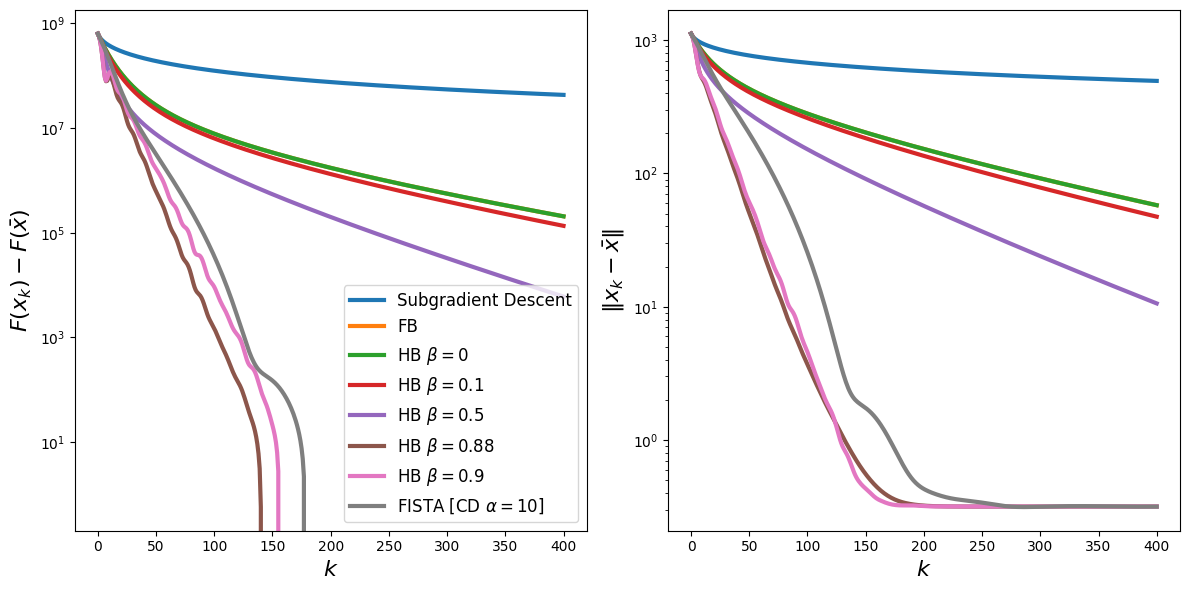

In [ ]:
# TODO: esegui fista con beta calcolato con Nesterov method
_, nest_x_iters, nest_fvals = fista(x0, gamma, get_beta_nest, T)
nest_fvals -= F_star

alpha= 10
ch_iters = []
ch_vals = []

_, ch_x_iters, ch_fvals = fista(x0, gamma, get_beta_chamb(alpha), T)
ch_iters.append(ch_x_iters)
ch_vals.append(ch_fvals - F_star)



betas = [ 0, 0.1, 0.5, 0.88, 0.9 ]
hb_iters = []
hb_vals = []
for beta in betas:
  _, hb_fvals, hb_x_iters = heavy_ball(x0, gamma, beta, T = T)
  hb_iters.append(hb_x_iters)
  hb_vals.append(hb_fvals - F_star)

labels = ['Subgradient Descent', 'FB'] + ['HB $\\beta = {}$'.format(beta) for beta in betas]+['FISTA [CD $\\alpha = 10$]']

x_iters = [sg_x_iters, pg_x_iters] + hb_iters + ch_iters
f_vals = [sg_fvals, pg_fvals] + hb_vals + ch_vals

plot_ls_results(labels, x_iters, f_vals, x_bar)